# Dashboard Visualisasi Evolusi StyleGAN2 (Tahap 1 - Tahap 6)

Notebook ini dirancang untuk membaca hasil pelatihan (log metric dan gambar fakes) dari seluruh tahap yang telah dilalui (Tahap 1 hingga Tahap 6) secara berurutan dan menggenerasi *dashboard* metrik untuk keperluan sidang/presentasi.


In [1]:
import os, glob, json, re, warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
import matplotlib.image as mpimg
import seaborn as sns

# ─── CONFIG ────────────────────────────────────────────────────────────────────
BASE    = r'output stylegan2'
# Asumsi path BASE disesuaikan ke folder 'output stylegan2' di direktori yg sama
OUT_DIR = r'output visualisasi sg2'
os.makedirs(OUT_DIR, exist_ok=True)

# Palette profesional
PALETTE = {'fid':'#2ecc71','aug':'#9b59b6','speed':'#e67e22',
           'vram':'#e74c3c','ram':'#3498db','accent':'#f39c12'}
BG   = '#0f1117'
CARD = '#1a1d27'
TXT  = '#e8eaf0'
GRID = '#2a2d3e'

def style_ax(ax, title='', xlabel='Kimg', ylabel=''):
    ax.set_facecolor(CARD)
    ax.tick_params(colors=TXT, labelsize=11)
    ax.xaxis.label.set_color(TXT); ax.yaxis.label.set_color(TXT)
    ax.spines[:].set_color(GRID)
    ax.grid(True, color=GRID, linewidth=0.7, alpha=0.8)
    if title: ax.set_title(title, color=TXT, fontsize=14, fontweight='bold', pad=12)
    if xlabel: ax.set_xlabel(xlabel, color=TXT, fontsize=12)
    if ylabel: ax.set_ylabel(ylabel, color=TXT, fontsize=12)


## 1. Pemrosesan Data & Log

Mengekstraksi *metrics* dari file `log.txt` dan `metric-fid50k_full.jsonl` untuk seluruh tahap dan menghitung kimg secara kumulatif agar tidak terjadi tumpang tindih urutan antar-tahap.


In [2]:
# ─── HARVEST DATA ──────────────────────────────────────────────────────────────
log_rows = []
fid_rows = []

stage_folders = ['tahap 1', 'tahap2', 'tahap3', 'tahap4', 'tahap5', 'tahap 6']
kimg_offset = 0

def parse_plain(line):
    d = {}
    for k,p in [('kimg',r'kimg\s+([\d\.]+)'),('sec',r'sec/kimg\s+([\d\.]+)'),
                ('aug',r'augment\s+([\d\.]+)'),('cpu',r'cpumem\s+([\d\.]+)'),
                ('gpu',r'gpumem\s+([\d\.]+)')]:
        m = re.search(p, line)
        if m: d[k] = float(m.group(1))
    return d if 'kimg' in d else None

# Kalkulasi akumulasi (offset) Kimg per tahap
stage_offsets = {}
current_offset = 0

for i, folder in enumerate(stage_folders):
    t_num = i + 1
    tahap_dir = os.path.join(BASE, folder)
    stage_offsets[t_num] = current_offset
    
    max_local_kimg = 0
    lf = os.path.join(tahap_dir, 'log.txt')
    if os.path.exists(lf):
        with open(lf) as f:
            for raw in f:
                d = parse_plain(raw.strip())
                if d and d['kimg'] > max_local_kimg:
                    max_local_kimg = d['kimg']
    current_offset += max_local_kimg

# Extract log details
for i, folder in enumerate(stage_folders):
    t_num = i + 1
    tahap_dir = os.path.join(BASE, folder)
    offset = stage_offsets[t_num]
    
    lf = os.path.join(tahap_dir, 'log.txt')
    ff = os.path.join(tahap_dir, 'metric-fid50k_full.jsonl')

    if os.path.exists(lf):
        with open(lf) as f:
            for raw in f:
                d = parse_plain(raw.strip())
                if d:
                    log_rows.append(dict(
                        Tahap=t_num, Kimg=d['kimg']+offset,
                        Sec=d.get('sec',0), Aug=d.get('aug',0),
                        CPU=d.get('cpu',0), GPU=d.get('gpu',0)))

    if os.path.exists(ff):
        with open(ff) as f:
            for line in f:
                line = line.strip()
                if not line: continue
                d = json.loads(line)
                pkl = os.path.basename(d.get('snapshot_pkl',''))
                try: local_k = int(pkl.replace('network-snapshot-','').replace('.pkl',''))
                except: continue
                fid_rows.append(dict(Kimg=offset+local_k,
                    FID=d['results']['fid50k_full'], Tahap=t_num))

df  = pd.DataFrame(log_rows).sort_values('Kimg').reset_index(drop=True)
dff = pd.DataFrame(fid_rows).sort_values('Kimg').drop_duplicates('Kimg').reset_index(drop=True)

print(f'Total Log entries: {len(df)} | Total FID entries: {len(dff)}')
if len(df) > 0 and len(dff) > 0:
    print(f'Rentang Kimg Keseluruhan : {df.Kimg.min():.0f} - {df.Kimg.max():.0f}')
    print(f'Rekor FID Terbaik        : {dff.FID.min():.2f} @ Kimg {dff.loc[dff.FID.idxmin(),"Kimg"]:.0f}')


Total Log entries: 1201 | Total FID entries: 51
Rentang Kimg Keseluruhan : 0 - 4780
Rekor FID Terbaik        : 59.49 @ Kimg 4380


## 2. Kurva Perkembangan FID (Semua Tahap)

Visualisasi garis (*line chart*) untuk memperlihatkan penurunan (*loss*) FID dari kimg 0 hingga ~4780 secara utuh. Daerah latar yang disoroti merepresentasikan batasan setiap tahap.


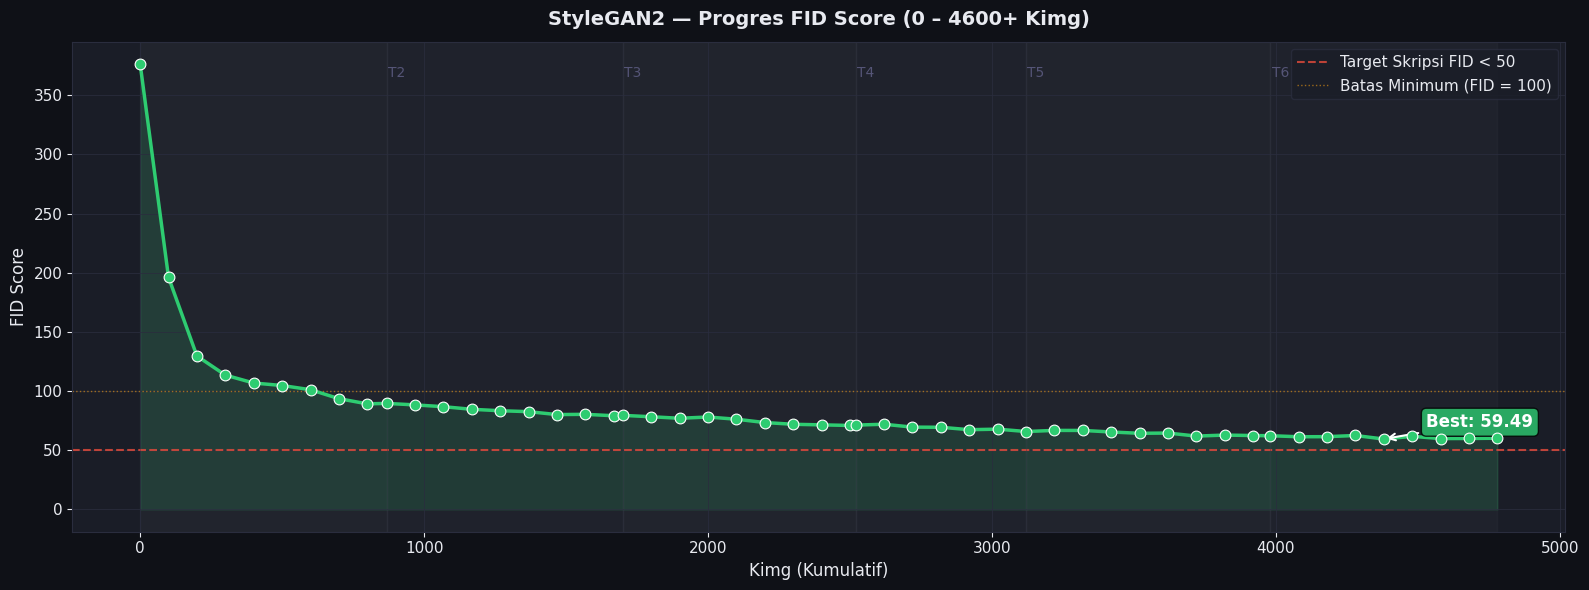

In [3]:
# ─── VIS 1: FID FULL CURVE ─────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(16,6))
fig.patch.set_facecolor(BG)
ax.set_facecolor(CARD)

if len(dff) > 0:
    ax.fill_between(dff.Kimg, dff.FID, alpha=0.15, color=PALETTE['fid'])
    ax.plot(dff.Kimg, dff.FID, color=PALETTE['fid'], lw=2.5, zorder=3)
    ax.scatter(dff.Kimg, dff.FID, color=PALETTE['fid'], s=60, zorder=4, edgecolors='white', lw=0.8)

    ax.axhline(50, color='#e74c3c', lw=1.5, linestyle='--', alpha=0.8, label='Target Skripsi FID < 50')
    ax.axhline(100, color=PALETTE['accent'], lw=1, linestyle=':', alpha=0.6, label='Batas Minimum (FID = 100)')

    # Anotasi FID Terbaik
    best_idx = dff.FID.idxmin()
    bk, bf = dff.loc[best_idx,'Kimg'], dff.loc[best_idx,'FID']
    ax.annotate(f'Best: {bf:.2f}',
        xy=(bk,bf), xytext=(bk+150, bf+10),
        color='white', fontsize=12, fontweight='bold',
        arrowprops=dict(arrowstyle='->', color='white', lw=1.5),
        bbox=dict(boxstyle='round,pad=0.3', facecolor=PALETTE['fid'], alpha=0.8))

    # Shading penanda setiap tahapan
    colors_tahap = ['#ffffff','#cccccc']
    for i, t in enumerate(stage_offsets.keys()):
        start = stage_offsets[t]
        end = stage_offsets.get(t+1, df.Kimg.max() if len(df) > 0 else 5000)
        ax.axvspan(start, end, alpha=0.03, color=colors_tahap[i%2])
        ax.axvline(start, color=GRID, lw=0.5, alpha=0.5)
        if start > 0:
            ax.text(start+5, dff.FID.max()*0.97, f'T{t}', color='#555577', fontsize=10)

style_ax(ax, 'StyleGAN2 — Progres FID Score (0 – 4600+ Kimg)', 'Kimg (Kumulatif)', 'FID Score')
ax.legend(facecolor=CARD, labelcolor=TXT, edgecolor=GRID, fontsize=11)
fig.tight_layout()
plt.show()


## 3. Komparasi Pencapaian FID per Tahap (Bar Chart)

Membandingkan skor FID pada titik terakhir (selesai) di setiap tahapannya.


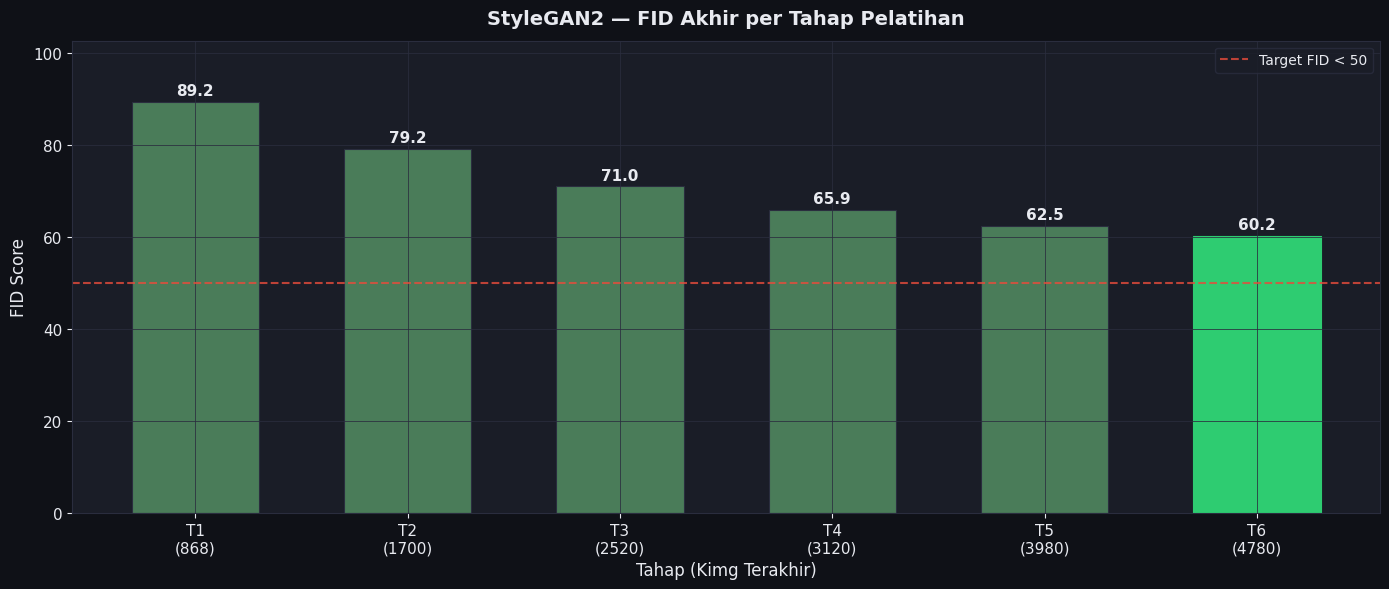

In [4]:
# ─── VIS 2: FID PER TAHAP ─────────────────────────────────────────
tahap_fid = []
for t in sorted(stage_offsets.keys()):
    sub = dff[dff.Tahap==t]
    if len(sub): 
        kimg_end = stage_offsets.get(t+1, df.Kimg.max())
        tahap_fid.append((f'T{t}\n({kimg_end:.0f})', sub.FID.iloc[-1]))

if tahap_fid:
    labels = [x[0] for x in tahap_fid]
    values = [x[1] for x in tahap_fid]
    
    fig, ax = plt.subplots(figsize=(14,6))
    fig.patch.set_facecolor(BG)
    ax.set_facecolor(CARD)
    bars = ax.bar(labels, values, color='#4a7c59', edgecolor=GRID, linewidth=0.8, width=0.6)
    
    # Highlight bar dengan nilai FID terbaik
    bars[values.index(min(values))].set_color(PALETTE['fid'])
    
    for bar, val in zip(bars, values):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+1.5,
                f'{val:.1f}', ha='center', color=TXT, fontsize=11, fontweight='bold')
                
    ax.axhline(50, color='#e74c3c', lw=1.5, linestyle='--', alpha=0.8, label='Target FID < 50')
    style_ax(ax, 'StyleGAN2 — FID Akhir per Tahap Pelatihan', 'Tahap (Kimg Terakhir)', 'FID Score')
    ax.legend(facecolor=CARD, labelcolor=TXT, edgecolor=GRID)
    ax.set_ylim(0, max(values)*1.15)
    fig.tight_layout()
    plt.show()


## 4. Evolusi Kualitas Gambar (Tahap 1 vs Akhir Tahap 6)

Memvisualisasikan output `fakes` dari awal mula pelatihan hingga akumulasi terakhir di Kimg ~4780.


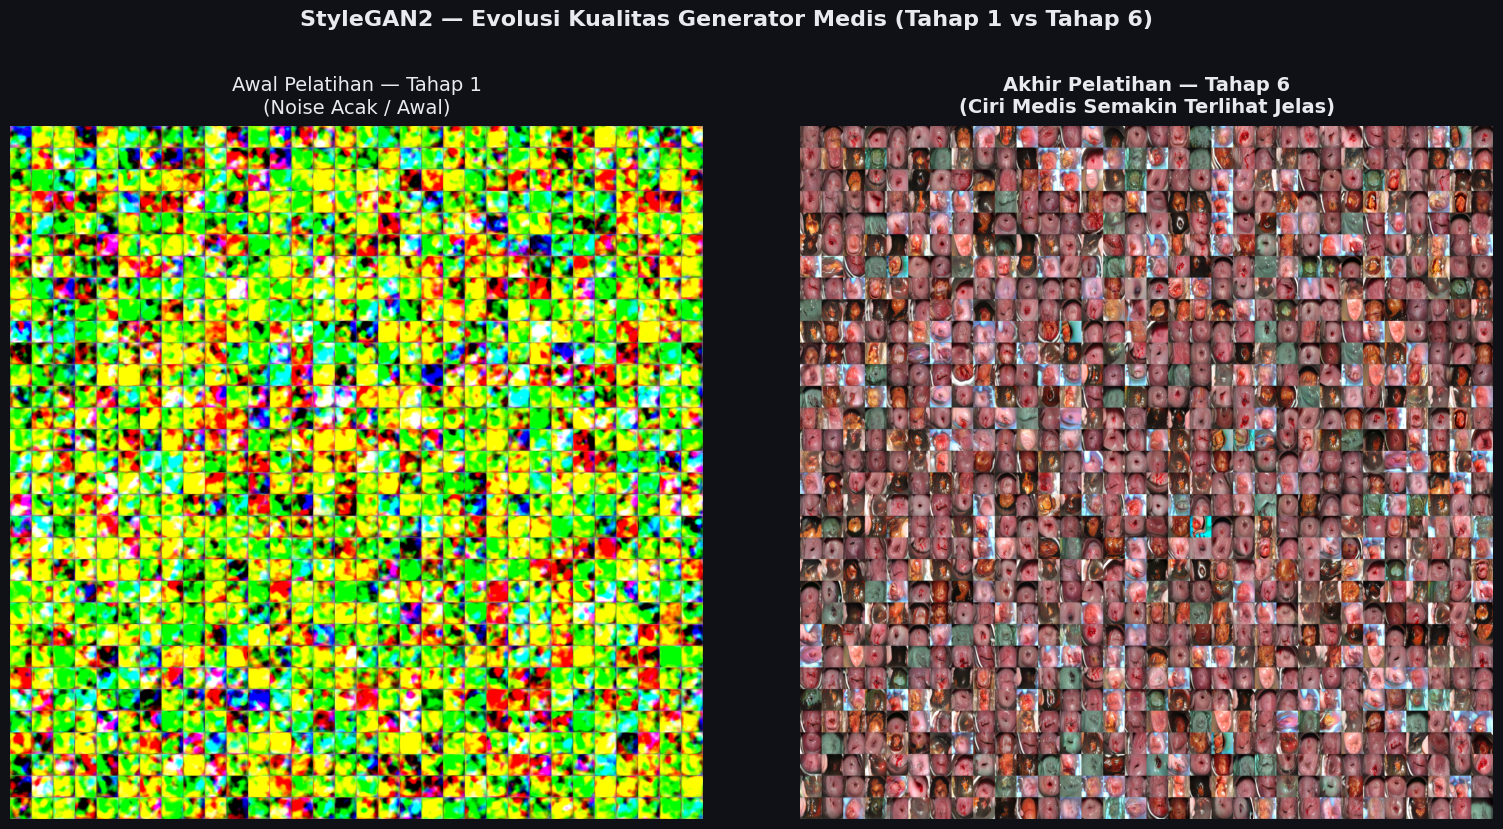

In [5]:
# ─── VIS 3: KOMPARASI GAMBAR AWAL vs AKHIR ───────────────────────────────────
fakes0 = os.path.join(BASE, stage_folders[0], 'fakes000000.png')

# Mendapatkan gambar fakes terakhir dari direktori tahap akhir (tahap 6)
last_stage_dir = os.path.join(BASE, stage_folders[-1])
fakes_in_last = sorted(glob.glob(os.path.join(last_stage_dir, 'fakes*.png')))
fakes_end = fakes_in_last[-1] if fakes_in_last else None

if os.path.exists(fakes0) and fakes_end and os.path.exists(fakes_end):
    fig = plt.figure(figsize=(20,9), facecolor=BG)
    gs = gridspec.GridSpec(1,2, figure=fig, wspace=0.04)
    for idx, (img_path, title, kimg_label) in enumerate([
        (fakes0, 'Awal Pelatihan — Tahap 1\n(Noise Acak / Awal)', '0 Kimg'),
        (fakes_end, f'Akhir Pelatihan — Tahap 6\n(Ciri Medis Semakin Terlihat Jelas)', '~4780 Kimg')
    ]):
        ax = fig.add_subplot(gs[idx])
        ax.imshow(mpimg.imread(img_path))
        ax.axis('off')
        ax.set_title(title, color=TXT, fontsize=14,
                     fontweight='bold' if idx==1 else 'normal', pad=10)
        # Menambahkan frame tebal pada gambar akhir
        if idx==1:
            for spine in ax.spines.values():
                spine.set_edgecolor(PALETTE['fid']); spine.set_linewidth(3); spine.set_visible(True)
                
    fig.suptitle('StyleGAN2 — Evolusi Kualitas Generator Medis (Tahap 1 vs Tahap 6)',
                 color=TXT, fontsize=16, fontweight='bold', y=1.01)
    plt.show()
else:
    print("Tidak dapat menemukan file fakes*.png pada Tahap 1 atau Tahap 6 untuk divisualisasikan.")


## 5. Super Dashboard (Ringkasan Keseluruhan)

Visualisasi komplit mulai dari Kurva FID, Kecepatan, Memori GPU RAM, hingga Augmentasi ADA.


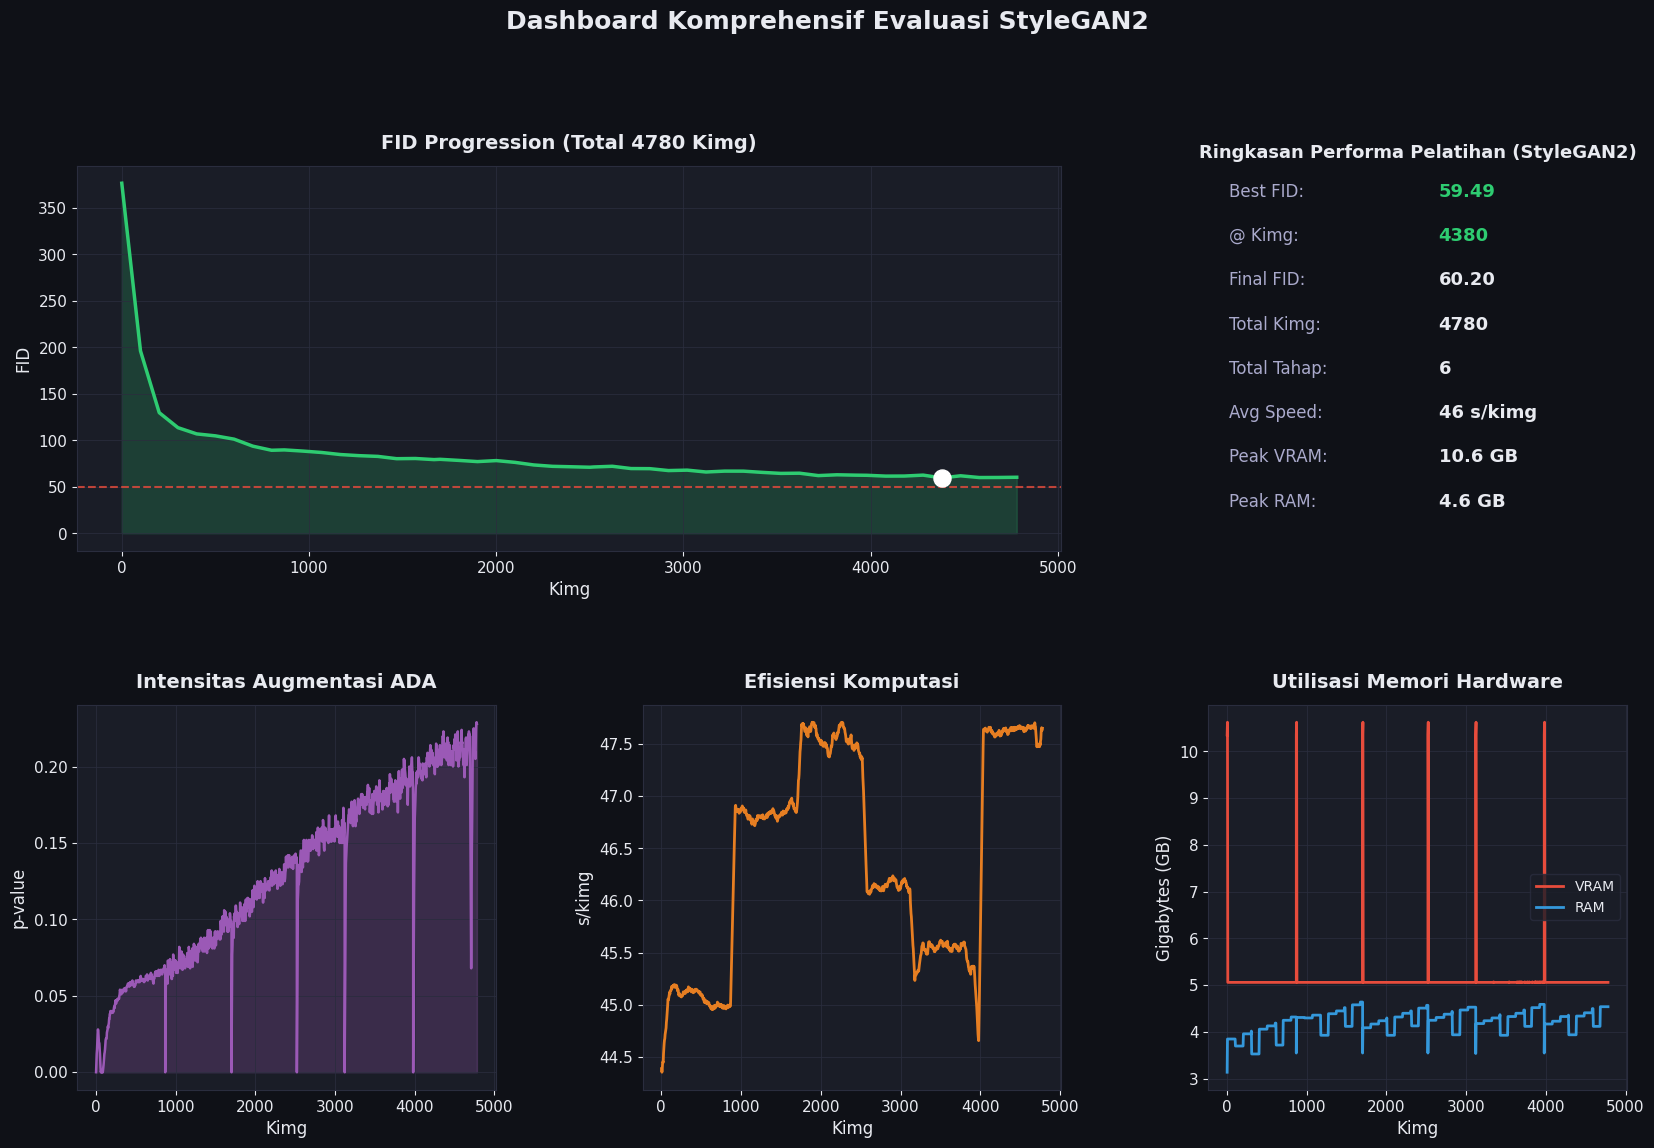

In [6]:
# ─── VIS 4: DASHBOARD RINGKASAN ───────────────────────────────────────────────
if len(dff) > 0 and len(df) > 0:
    fig = plt.figure(figsize=(20,12), facecolor=BG)
    gs = gridspec.GridSpec(2,3, figure=fig, hspace=0.4, wspace=0.35)

    # Main FID Panel
    ax1 = fig.add_subplot(gs[0,:2])
    ax1.set_facecolor(CARD)
    ax1.fill_between(dff.Kimg, dff.FID, alpha=0.2, color=PALETTE['fid'])
    ax1.plot(dff.Kimg, dff.FID, color=PALETTE['fid'], lw=2.5)
    ax1.scatter([bk],[bf], s=150, color='white', zorder=5)
    ax1.axhline(50, color='#e74c3c', lw=1.5, linestyle='--', alpha=0.8)
    style_ax(ax1,f'FID Progression (Total {df.Kimg.max():.0f} Kimg)','Kimg','FID')

    # Statistic Summary Card
    ax2 = fig.add_subplot(gs[0,2])
    ax2.set_facecolor(CARD); ax2.axis('off')
    stats = [
        ('Best FID', f'{dff.FID.min():.2f}'),
        ('@ Kimg', f'{bk:.0f}'),
        ('Final FID', f'{dff.FID.iloc[-1]:.2f}'),
        ('Total Kimg', f'{df.Kimg.max():.0f}'),
        ('Total Tahap', f'{len(stage_folders)}'),
        ('Avg Speed', f'{df[df.Sec<500].Sec.mean():.0f} s/kimg'),
        ('Peak VRAM', f'{df.GPU.max():.1f} GB'),
        ('Peak RAM', f'{df.CPU.max():.1f} GB'),
    ]
    for i,(k,v) in enumerate(stats):
        ax2.text(0.05, 0.92-i*0.115, k+':', color='#aaaacc', fontsize=12, transform=ax2.transAxes)
        ax2.text(0.55, 0.92-i*0.115, v, color=PALETTE['fid'] if i<2 else TXT,
                 fontsize=13, fontweight='bold', transform=ax2.transAxes)
    ax2.set_title('Ringkasan Performa Pelatihan (StyleGAN2)', color=TXT, fontsize=13, fontweight='bold')

    # Augmentation Panel
    ax3 = fig.add_subplot(gs[1,0])
    ax3.set_facecolor(CARD)
    ax3.fill_between(df.Kimg, df.Aug, alpha=0.25, color=PALETTE['aug'])
    ax3.plot(df.Kimg, df.Aug, color=PALETTE['aug'], lw=1.8)
    style_ax(ax3,'Intensitas Augmentasi ADA','Kimg','p-value')

    # Computation Speed Panel
    ax4 = fig.add_subplot(gs[1,1])
    ax4.set_facecolor(CARD)
    df_s = df[df.Sec<500]
    ax4.plot(df_s.Kimg, df_s.Sec.rolling(15,min_periods=1).mean(), color=PALETTE['speed'], lw=2)
    style_ax(ax4,'Efisiensi Komputasi','Kimg','s/kimg')

    # Hardware Memory Panel
    ax5 = fig.add_subplot(gs[1,2])
    ax5.set_facecolor(CARD)
    ax5.plot(df.Kimg, df.GPU, color=PALETTE['vram'], lw=2, label='VRAM')
    ax5.plot(df.Kimg, df.CPU, color=PALETTE['ram'], lw=2, label='RAM')
    ax5.legend(facecolor=CARD, labelcolor=TXT, edgecolor=GRID, fontsize=10)
    style_ax(ax5,'Utilisasi Memori Hardware','Kimg','Gigabytes (GB)')

    fig.suptitle('Dashboard Komprehensif Evaluasi StyleGAN2', color=TXT, fontsize=18, fontweight='bold', y=1.01)
    plt.show()
